# Practical 1: Fibonacci Numbers (Iterative vs Recursive)

Fibonacci Series (First 10 terms): [0, 1, 1, 2, 3, 5, 8, 13, 21, 34]
Iterative Steps: 9 | Recursive Calls for F(9): 109


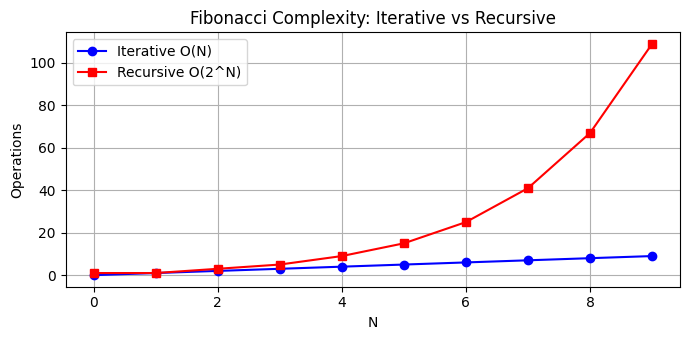

In [6]:
# Practical 1: Fibonacci Numbers (Iterative vs Recursive)
import matplotlib.pyplot as plt

n = 10

# Iterative Approach
def fib_iter(num):
    a, b, res = 0, 1, []
    for _ in range(num):
        res.append(a)
        a, b = b, a + b
    return res

# Recursive Approach
rec_count = 0
def fib_rec(k):
    global rec_count
    rec_count += 1
    return k if k <= 1 else fib_rec(k - 1) + fib_rec(k - 2)

iter_res = fib_iter(n)
calls = []
for i in range(n):
    rec_count = 0
    fib_rec(i)
    calls.append(rec_count)

print(f"Fibonacci Series (First {n} terms): {iter_res}")
print(f"Iterative Steps: {n - 1} | Recursive Calls for F({n - 1}): {calls[-1]}")

plt.figure(figsize=(7, 3.5))
plt.plot(range(n), range(n), marker="o", color="blue", label="Iterative O(N)")
plt.plot(range(n), calls, marker="s", color="red", label="Recursive O(2^N)")
plt.title("Fibonacci Complexity: Iterative vs Recursive")
plt.xlabel("N"); plt.ylabel("Operations"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()


# Practical 2: Huffman Encoding (Greedy Approach)

Text: "BCAADDDCCACACAC" | Unique Chars: 4
Huffman Codes: {'C': '0', 'B': '100', 'D': '101', 'A': '11'}
Encoded Bits: 28 bits | Storage Saved: 76.67%


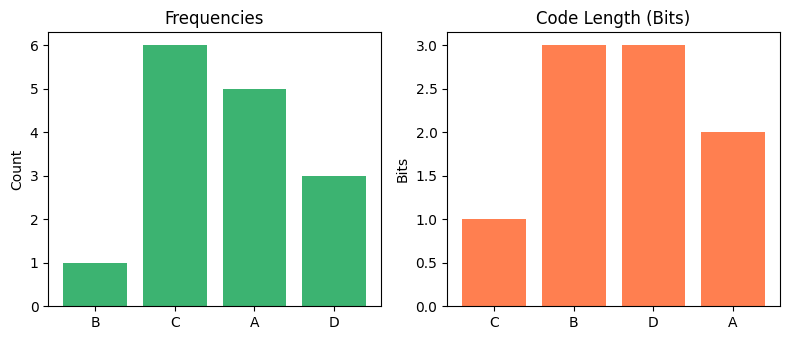

In [7]:
# Practical 2: Huffman Encoding (Greedy)
import heapq, matplotlib.pyplot as plt
from collections import Counter

text = "BCAADDDCCACACAC"
freq = Counter(text)

heap = [[f, [ch, ""]] for ch, f in freq.items()]
heapq.heapify(heap)

while len(heap) > 1:
    left, right = heapq.heappop(heap), heapq.heappop(heap)
    for item in left[1:]: item[1] = "0" + item[1]
    for item in right[1:]: item[1] = "1" + item[1]
    heapq.heappush(heap, [left[0] + right[0]] + left[1:] + right[1:])

codes = {ch: code for ch, code in heap[0][1:]}
encoded = "".join(codes[ch] for ch in text)
savings = (1 - len(encoded) / (len(text) * 8)) * 100

print(f"Text: \"{text}\" | Unique Chars: {len(freq)}")
print(f"Huffman Codes: {codes}")
print(f"Encoded Bits: {len(encoded)} bits | Storage Saved: {savings:.2f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))
ax1.bar(freq.keys(), freq.values(), color="mediumseagreen")
ax1.set_title("Frequencies"); ax1.set_ylabel("Count")

ax2.bar(codes.keys(), [len(c) for c in codes.values()], color="coral")
ax2.set_title("Code Length (Bits)"); ax2.set_ylabel("Bits")

plt.tight_layout()
plt.show()


# Practical 3: Fractional Knapsack (Greedy Approach)

Knapsack Capacity: 50 | Items: [('Item 1', 10, 60), ('Item 2', 20, 100), ('Item 3', 30, 120)]
Max Value: $240.00 | Fractions Taken: [1.0, 1.0, 0.6666666666666666]


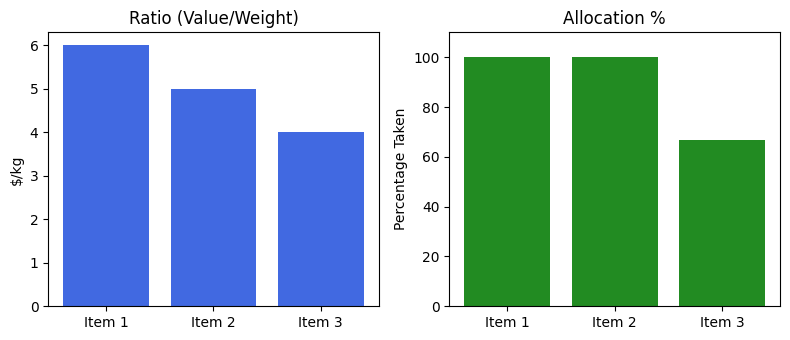

In [8]:
# Practical 3: Fractional Knapsack (Greedy)
import matplotlib.pyplot as plt

capacity = 50
items = [("Item 1", 10, 60), ("Item 2", 20, 100), ("Item 3", 30, 120)] # (name, weight, value)
items.sort(key=lambda x: x[2] / x[1], reverse=True)

curr_cap, total_val, fractions = capacity, 0.0, []
for name, wt, val in items:
    if curr_cap >= wt:
        curr_cap -= wt
        total_val += val
        fractions.append(1.0)
    elif curr_cap > 0:
        frac = curr_cap / wt
        total_val += val * frac
        fractions.append(frac)
        curr_cap = 0
    else:
        fractions.append(0.0)

print(f"Knapsack Capacity: {capacity} | Items: {items}")
print(f"Max Value: ${total_val:.2f} | Fractions Taken: {fractions}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))
names = [x[0] for x in items]
ax1.bar(names, [x[2] / x[1] for x in items], color="royalblue")
ax1.set_title("Ratio (Value/Weight)"); ax1.set_ylabel("$/kg")

ax2.bar(names, [f * 100 for f in fractions], color="forestgreen")
ax2.set_title("Allocation %"); ax2.set_ylabel("Percentage Taken")
ax2.set_ylim(0, 110)

plt.tight_layout()
plt.show()


# Practical 4: 0/1 Knapsack (Dynamic Programming)

Weights: [10, 20, 30] | Values: [60, 100, 120] | Capacity: 50
Max Value: $220 | Selected Items: [2, 3]


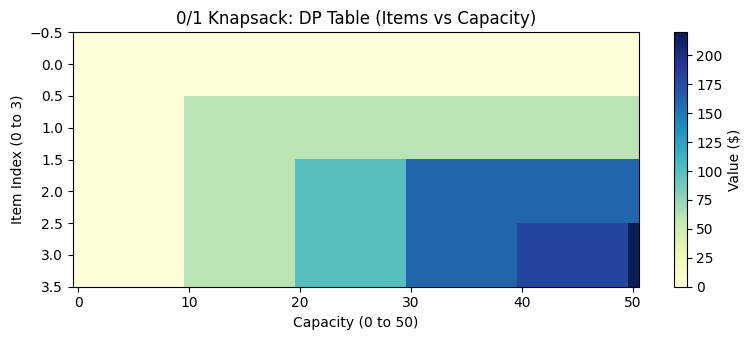

In [9]:
# Practical 4: 0/1 Knapsack (Dynamic Programming)
import matplotlib.pyplot as plt

weights = [10, 20, 30]
values = [60, 100, 120]
capacity = 50
n = len(weights)

dp = [[0] * (capacity + 1) for _ in range(n + 1)]
for i in range(1, n + 1):
    for w in range(1, capacity + 1):
        if weights[i - 1] <= w:
            dp[i][w] = max(values[i - 1] + dp[i - 1][w - weights[i - 1]], dp[i - 1][w])
        else:
            dp[i][w] = dp[i - 1][w]

# Backtracking selected items
w, selected = capacity, []
for i in range(n, 0, -1):
    if dp[i][w] != dp[i - 1][w]:
        selected.append(i)
        w -= weights[i - 1]

print(f"Weights: {weights} | Values: {values} | Capacity: {capacity}")
print(f"Max Value: ${dp[n][capacity]} | Selected Items: {selected[::-1]}")

plt.figure(figsize=(8, 3.5))
plt.imshow(dp, cmap="YlGnBu", aspect="auto")
plt.colorbar(label="Value ($)")
plt.title("0/1 Knapsack: DP Table (Items vs Capacity)")
plt.xlabel("Capacity (0 to 50)"); plt.ylabel("Item Index (0 to 3)")
plt.tight_layout()
plt.show()


# Practical 5: N-Queens Problem (Backtracking)

Total Solutions for N=4: 2
Solution 1 Board:
. Q . .
. . . Q
Q . . .
. . Q .


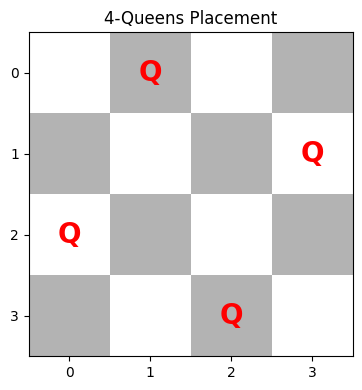

In [11]:
# Practical 5: N-Queens Problem (Backtracking)
import numpy as np, matplotlib.pyplot as plt

n = 4

def is_safe(board, row, col):
    for i in range(row):
        if board[i][col] == 1: return False
    for i, j in zip(range(row - 1, -1, -1), range(col - 1, -1, -1)):
        if board[i][j] == 1: return False
    for i, j in zip(range(row - 1, -1, -1), range(col + 1, n)):
        if board[i][j] == 1: return False
    return True

solutions = []
def solve(board, row):
    if row == n:
        solutions.append([r[:] for r in board])
        return
    for col in range(n):
        if is_safe(board, row, col):
            board[row][col] = 1
            solve(board, row + 1)
            board[row][col] = 0

board = [[0] * n for _ in range(n)]
solve(board, 0)

print(f"Total Solutions for N={n}: {len(solutions)}")
print(f"Solution 1 Board:\n" + "\n".join([" ".join(["Q" if x else "." for x in r]) for r in solutions[0]]))

# Plot Chessboard
checkered = np.indices((n, n)).sum(axis=0) % 2
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(checkered, cmap="binary", alpha=0.3)
for r in range(n):
    for c in range(n):
        if solutions[0][r][c] == 1:
            ax.text(c, r, "Q", fontsize=20, ha="center", va="center", color="red", fontweight="bold")
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_title(f"{n}-Queens Placement")
plt.tight_layout()
plt.show()
